If U is uniform on [0,1] and F is a continuosly increasing CDF, we can prove the inverse has CDF F.

$$F(x) = \frac{x-a}{b-a} = u$$

If we set the probability of the uniform distribution to U, we can solve in terms of X.

$$F^{-1}(u) = a + (b - a)u = x$$

When a = 0 and b = 1,

$$F^{-1}(u) = u = x$$ so $$u = x$$

To derive $$F^(-1)$$ for the exponential, we follow a similar path as before.

The PDF of the exponential is $$f(x) = \lambda e^{-\lambda x}$$

From there, the CDF is $$F(x) = 1-e^{-\lambda x}$$

We define u as $$u = 1-e^{-\lambda x}$$

$$u-1 = -e^{-\lambda x}$$

$$1-u = e^{-\lambda x}$$
$$ln(1-u) = ln(e^{-\lambda x})$$
$$-\frac{1}{\lambda} ln(1-u) = x$$

For the Rayleigh, we can use the same process:

$$f(x) = \frac{x}{\sigma^2} e^{\frac{-x^2}{2\sigma ^2}}$$

The CDF is:

$$f(x) = 1 - e^{\frac{-x^2}{2\sigma ^2}} = u$$

$$u = 1 - e^{\frac{-x^2}{2\sigma ^2}}$$

$$u - 1 = e^{\frac{-x^2}{2\sigma ^2}}$$

$$ln (u - 1) = ln(e^{\frac{-x^2}{2\sigma ^2}})$$

$$ln (u - 1) = \frac{-x^2}{2\sigma ^2}$$

$$2\sigma^2 ln (u - 1) = {-x^2}$$

$$\sqrt{-2\sigma^2 ln (u - 1)} = x$$

In [36]:
import mp2lib
import importlib
importlib.reload(mp2lib)
import numpy as np
import matplotlib.pyplot as plt

from mp2lib import (
    inv_cdf_exponential,
    inv_cdf_rayleigh,
    sample_by_inversion,
    ks_statistic
)

Rayleigh KS statistic: 0.001734
Exponent KS statistic: 0.002087


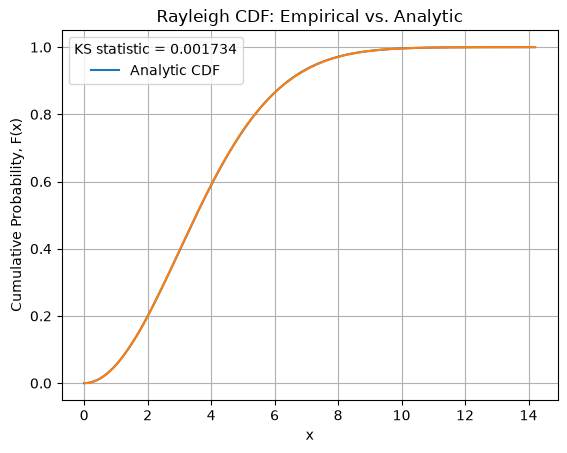

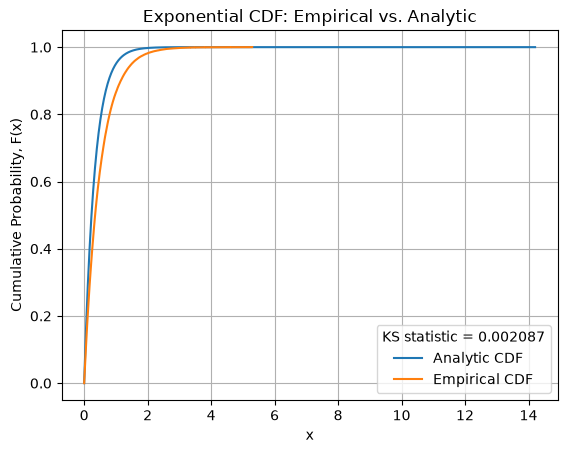

In [34]:
SEED = 555663236  # Previously drawn example seed.
n = 100000

rng = np.random.default_rng(SEED)

ray_samples  = sample_by_inversion(inv_cdf_rayleigh, n, rng, sigma=3.0)

exp_samples = sample_by_inversion(inv_cdf_exponential, n, rng, lam=2.0)



def cdf_rayleigh(x, sigma):
    x = np.asarray(x, dtype=float)
    return 1 - np.exp(-(x**2) / (2 * sigma**2))
    
def cdf_exp(x, lamb):
    return 1 - np.exp(-lamb*x)
sigma = 3.0
lamb = 2.0
ks_rayleigh = ks_statistic(ray_samples, lambda x: cdf_rayleigh(x, sigma))
print(f"Rayleigh KS statistic: {ks_rayleigh:.6f}")


ks_exp = ks_statistic(exp_samples, lambda x: cdf_exp(x, lamb))
print(f"Exponent KS statistic: {ks_exp:.6f}")


# Plot the histogram for Rayleigh
#plt.hist(ray_samples, bins=100, density=True, alpha=0.7, color='blue', edgecolor='black')
#plt.title('Histogram of Rayleigh Samples via Inverse CDF Method')
#plt.xlabel('x')
#plt.ylabel('Density')
#plt.grid(True)

x_sorted = np.sort(ray_samples)
m = len(x_sorted)

p = np.arange(1, m + 1) / m
x_ray_grid = np.linspace(0, x_sorted.max(), 1000)

plt.plot(
    x_ray_grid,
    cdf_rayleigh(x_ray_grid, sigma),
    label="Analytic CDF"
)
plt.title("Rayleigh CDF: Empirical vs. Analytic")
plt.xlabel("x")
plt.ylabel("Cumulative Probability, F(x)")
plt.legend(title=f"KS statistic = {ks_rayleigh:.6f}")
plt.grid(True)


plt.step(x_sorted, p, where="post", label="Empirical CDF")
plt.show()

# Plot the histogram for Exponential
#plt.figure(figsize=(10, 6))
#plt.hist(exp_samples, bins=100, density=True, alpha=0.7, color='blue', edgecolor='black')
#plt.title('Histogram of Exponential Samples via Inverse CDF Method')
#plt.xlabel('x')
#plt.ylabel('Density')
#plt.grid(True)
x2_sorted = np.sort(exp_samples)
m2 = len(x2_sorted)

p = np.arange(1, m2 + 1) / m2
x_ray_grid = np.linspace(0, x_sorted.max(), 1000)

plt.plot(
    x_ray_grid,
    cdf_exp(x_ray_grid, sigma),
    label="Analytic CDF"
)

plt.step(x2_sorted, p, where="post", label="Empirical CDF")
plt.title("Exponential CDF: Empirical vs. Analytic")
plt.xlabel("x")
plt.ylabel("Cumulative Probability, F(x)")
plt.legend(title=f"KS statistic = {ks_exp:.6f}")
plt.grid(True)
plt.show()





My function uses the inverse exponential CDF form of 
$$F^{-1}(u) = \frac{-ln(1-u)}{\lambda}$$ 

and 
$$F^{-1}{u} = \sigma \sqrt{2ln(1-u)}$$ for the inverse Rayleigh form.

When u = 0, both forms will have ln(1) = 0, which will safely fail by becoming zero instead of infinity.  However, additional code was added to prevent it from being exactly 1, which could lead to ln(0), which is infinity.  This means the range is [0,1), with it not including 1 exactly.


The exponential inverse can be written either 
$$-\frac{ln(1-U)}{\lambda}$$

or

$$-\frac{ln(U)}{\lambda}$$

Both of these results are the same, but we use the second one because we will not have the same issue with the edge case of zero.  Instead of going to infinity, the function will fail safely by returning zero.